# CV03 — Phân tích ACF/PACF và đề xuất bậc ARIMA

**Phụ trách** · Trâm, Nhóm 7

Bài 4 dùng chuỗi doanh số thuốc theo tháng a10 để đọc ACF/PACF đến lag 40. Phân tích dùng 80% quan sát đầu theo thời gian. Khi CV01 đã xuất `data/processed/train.csv`, notebook dùng tệp đó. Nếu chưa có, notebook tạo tập train tạm từ dữ liệu gốc theo cùng quy tắc chia.

In [1]:
import sys
from pathlib import Path
from tempfile import TemporaryDirectory

import pandas as pd
from IPython.display import Image, display

root = next(
    path for path in (Path.cwd(), *Path.cwd().parents, Path.cwd() / "time-series-lab2")
    if (path / "src" / "cv03_acf_pacf_analysis.py").is_file()
)
sys.path.insert(0, str(root / "src"))

from cv03_acf_pacf_analysis import (
    SEASONAL_LAGS, TRAIN_CSV, generate_candidate_orders, lag_correlations,
    load_differenced_train, plot_acf_pacf, plot_lag_analysis,
)

if TRAIN_CSV.is_file():
    series = load_differenced_train(TRAIN_CSV)
else:
    raw = pd.read_csv(root / "data" / "raw" / "a10.csv", parse_dates=["date"])
    train = raw.sort_values("date").iloc[:int(0.8 * len(raw))]
    with TemporaryDirectory() as tmp:
        train_path = Path(tmp) / "train.csv"
        train.to_csv(train_path, index=False)
        series = load_differenced_train(train_path)

print(f"{len(series)} quan sát sau sai phân từ {series.index[0]:%m/%Y} đến {series.index[-1]:%m/%Y}.")
print(f"Ngưỡng 95% xấp xỉ ±{1.96 / len(series)**0.5:.3f}.")

162 quan sát sau sai phân từ 08/1991 đến 01/2005.
Ngưỡng 95% xấp xỉ ±0.154.


## ACF và PACF đến lag 40

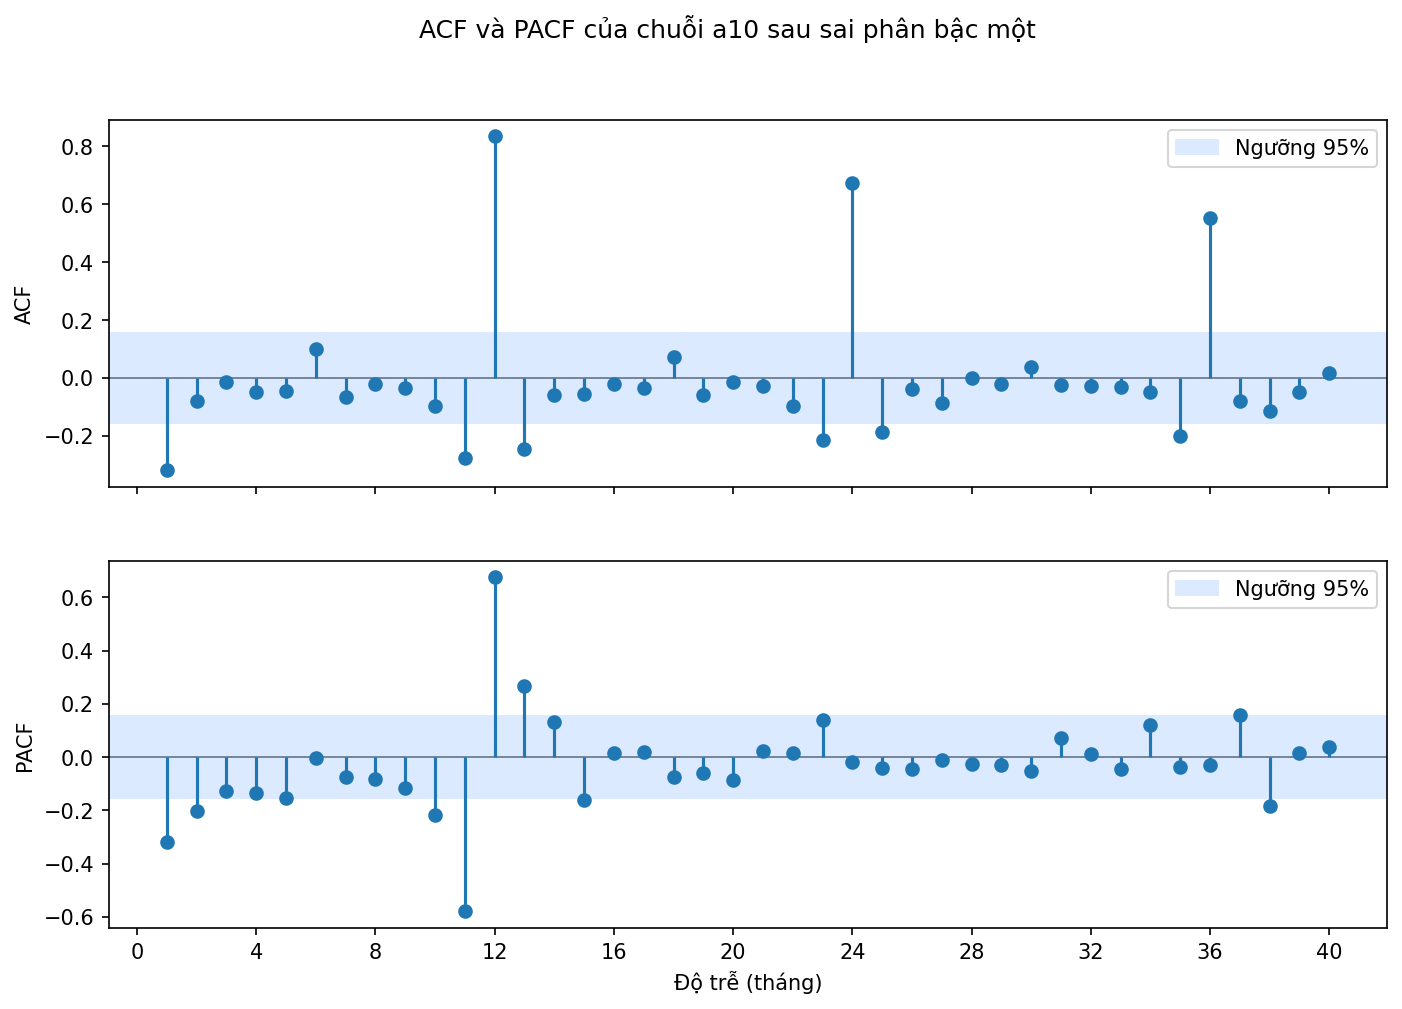

,ACF,PACF
Lag,,
1,-0.319,-0.319
2,-0.079,-0.202
3,-0.014,-0.126
10,-0.095,-0.218
11,-0.277,-0.580
12,0.835,0.676
13,-0.246,0.265
23,-0.213,0.141
24,0.675,-0.019


In [2]:
display(Image(filename=str(plot_acf_pacf(series))))
correlations = lag_correlations(series)
display(correlations.loc[[1, 2, 3, 10, 11, 12, 13, 23, 24, 25, 35, 36]].round(3))

## Tương quan mùa vụ 12 tháng

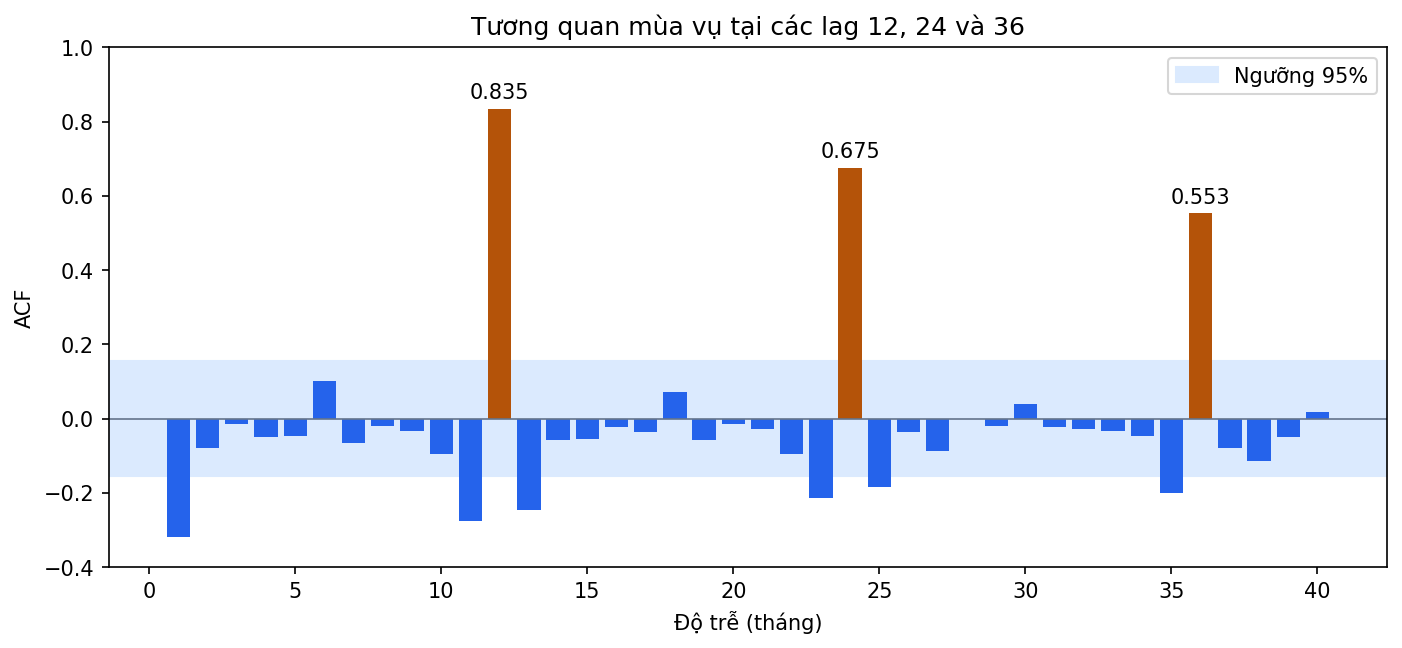

In [3]:
display(Image(filename=str(plot_lag_analysis(series))))

## Trả lời Bài 4

1. **ACF giảm nhanh sau lag 1 ở nhóm độ trễ ngắn.** ACF tại lag 1 là −0,319, còn lag 2 và 3 nằm trong dải 95% xấp xỉ. ACF bật lên rõ ở lag 12, 24 và 36 (lần lượt 0,835, 0,675 và 0,553). Các đỉnh giảm dần qua các chu kỳ và cho thấy mùa vụ còn lại sau sai phân bậc một.
2. **PACF vượt ngưỡng ở lag 1 và 2 rồi yếu đi ở các lag ngắn tiếp theo.** Giá trị tại lag 1 và 2 lần lượt là −0,319 và −0,202. PACF có gai lớn quanh lag 11–13, nên dấu hiệu cắt sau lag 2 chỉ là gợi ý khi đọc nhóm lag ngắn. Dải ±1,96/√N là ngưỡng xấp xỉ cho từng lag.
3. **Đề xuất thử ARIMA(1,1,1) và ARIMA(2,1,1).** Cả hai dùng sai phân thường bậc một. Tín hiệu ACF ngắn hạn gợi ý thử q = 1. Lag 2 của PACF là căn cứ để thử thêm p = 2 bên cạnh cấu hình gọn p = 1. CV04 sẽ kiểm chứng bằng AIC/BIC và chẩn đoán phần dư. Các đỉnh ACF theo bội số 12 là căn cứ để CV05 khảo sát SARIMA với chu kỳ s = 12.

Bảng CSV đặt hai cấu hình ưu tiên lên đầu và giữ các cấu hình nhỏ còn lại để đối chiếu.

In [4]:
display(generate_candidate_orders())

,p,d,q,Ghi chú
0,1,1,1,Khởi điểm gọn; ACF và PACF đều vượt ngưỡng tại...
1,2,1,1,Thử thêm một bậc AR; PACF vượt ngưỡng tại lag 2.
2,0,1,0,Ứng viên đối chiếu
3,0,1,1,Ứng viên đối chiếu
4,0,1,2,Ứng viên đối chiếu
5,1,1,0,Ứng viên đối chiếu
6,1,1,2,Ứng viên đối chiếu
7,2,1,0,Ứng viên đối chiếu
8,2,1,2,Ứng viên đối chiếu
